# 45 - Proposition 1 and Corollary 1 on three forget sets

Notebook 30 tested the factorization of the decoder-output Fisher cosine, $\cos(F^F, F^R) = \cos(\sigma^F, \sigma^R)\,\cos(\nu^F, \nu^R)$,
on PBMC-33k cluster 13 alone. This notebook runs one procedure on that forget set and on both PBMC-68k forget sets
(`scripts/proposition_test.py`): the retain Fisher of the output weight matrix comes from the cache written by
`train_fisher_unlearn.py` (per-sample diagonal empirical Fisher, eval mode, z = mu, damping 0), the forget Fisher is
computed fresh with the same estimator, and the two factors are read from the Fisher marginals (row sums over
hidden units give the gene profile $\sigma$, column sums over genes give the hidden-unit profile $\nu$) and, as
the proposition's stronger idealization, directly from residual variances and hidden second moments.

The corollary's part (i) is applied in its general form. For any gene set $S$, with $m_S$ the share of a
profile's squared norm on $S$,
$\cos(\sigma^F, \sigma^R) \ge \cos(\sigma^F_S, \sigma^R_S)\sqrt{m^F_S\, m^R_S}$
because every entry is nonnegative; the paper's counting bound $(D-M)/(D-M+MV^2)$ is the special case in
which the shared genes have equal residual variance. $S$ is the set of genes inside both profiles' top-90-percent
sets. The same inequality applied to $\nu$ shows how many hidden units carry each set through the decoder.

In [1]:
import sys, json
sys.path.insert(0, '../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import canonical as C
pt = C.proposition_test()['cohorts']
names = {'pbmc33k_c13': 'PBMC-33k cluster 13', 'pbmc68k_mk': 'PBMC-68k cluster 9', 'pbmc68k_pdc': 'PBMC-68k cluster 8'}
rows = []
for k, e in pt.items():
    m, d, t1, ss, nu = e['fisher_marginals'], e['direct_data'], e['svd_top1_share'], e['corollary_i_shared_support'], e['nu_shared_support']
    rows.append({'forget set': names[k], 'n forget': e['n_forget'], 'n retain': e['n_retain_cache'],
                 'measured cos(F^F, F^R)': e['measured_cosine'], 'cos sigma (marginals)': m['cos_sigma'], 'cos nu (marginals)': m['cos_nu'],
                 'product (marginals)': m['product'], 'ratio to measured': m['ratio_product_over_measured'],
                 'cos sigma (direct)': d['cos_sigma'], 'cos nu (direct)': d['cos_nu'], 'product (direct)': d['product'],
                 'top-1 share F': t1['forget'], 'top-1 share R': t1['retain'],
                 'shared-support bound on cos sigma': ss['bound'], '|S| genes': ss['n_S'], 'cos on S': ss['cos_S'], 'mass F on S': ss['mass_forget_S'], 'mass R on S': ss['mass_retain_S'],
                 'hidden units for 90% (F)': nu['n_top90_forget'], 'hidden units for 90% (R)': nu['n_top90_retain'], 'shared units': nu['n_S']})
df = pd.DataFrame(rows).set_index('forget set'); df.round(3)

,n forget,n retain,"measured cos(F^F, F^R)",cos sigma (marginals),cos nu (marginals),product (marginals),ratio to measured,cos sigma (direct),cos nu (direct),product (direct),top-1 share F,top-1 share R,shared-support bound on cos sigma,|S| genes,cos on S,mass F on S,mass R on S,hidden units for 90% (F),hidden units for 90% (R),shared units
forget set,,,,,,,,,,,,,,,,,,,,
PBMC-33k cluster 13,30,28094,0.485,0.830,0.600,0.498,1.027,0.845,0.572,0.483,0.975,0.943,0.658,99,0.898,0.772,0.696,82,30,12
PBMC-68k cluster 9,107,57958,0.018,0.329,0.057,0.019,1.024,0.631,0.054,0.034,0.998,0.941,0.210,21,0.940,0.227,0.221,5,282,0
PBMC-68k cluster 8,302,57763,0.117,0.718,0.170,0.122,1.048,0.904,0.176,0.159,0.990,0.940,0.522,56,0.958,0.494,0.600,40,282,23


## The factor profiles

Each point is one hidden unit of the decoder's last layer (top row, the profile $\nu$) or one gene (bottom row, the
profile $\sigma$), placed by its share of the retain profile against its share of the forget profile, on log axes with
the diagonal drawn. Points on the diagonal are used alike by the two sets; points far below it are used by the forget set
and not the retain set. On PBMC-33k the megakaryocytes' main hidden units are the retain set's main hidden units; on
PBMC-68k cluster 9 the five units that carry 90 percent of the forget profile sit at the bottom right, used by the
megakaryocytes and by almost nothing else, which is where the decoder-output overlap of 0.02 comes from and why the
Fisher scrub is not undone there.

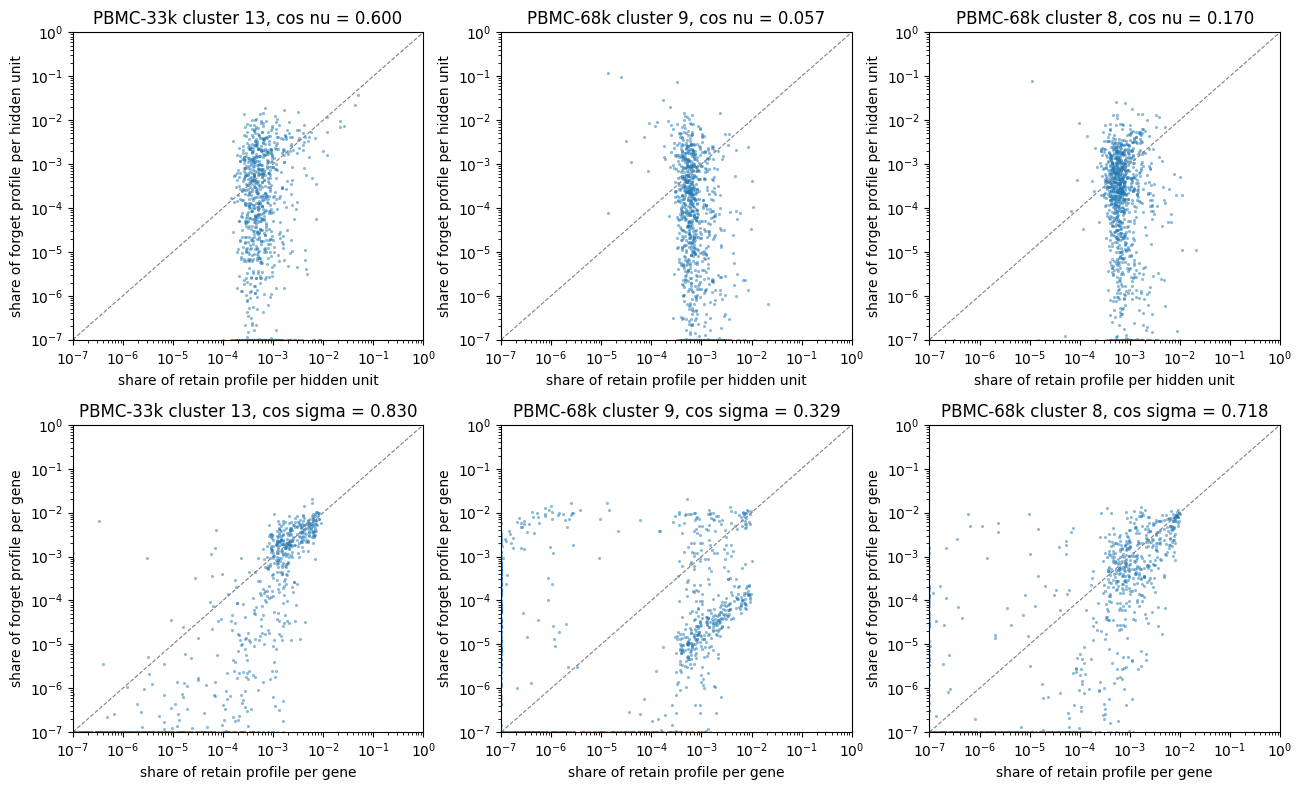

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
floor = 1e-7
for j, (k, e) in enumerate(pt.items()):
    v = e['vectors']; m = e['fisher_marginals']
    for i, (key, lab, cos) in enumerate((('nu', 'hidden unit', m['cos_nu']), ('sigma', 'gene', m['cos_sigma']))):
        f, r = np.array(v[f'{key}_forget']), np.array(v[f'{key}_retain']); f, r = f / f.sum(), r / r.sum()
        ax = axes[i, j]; ax.scatter(np.clip(r, floor, None), np.clip(f, floor, None), s=5, alpha=0.5, lw=0)
        lim = (floor, 1.0); ax.plot(lim, lim, color='gray', lw=0.8, ls='--'); ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(lim); ax.set_ylim(lim)
        ax.set_xlabel(f'share of retain profile per {lab}'); ax.set_ylabel(f'share of forget profile per {lab}')
        ax.set_title(f"{names[k]}, cos {key} = {cos:.3f}")
plt.tight_layout(); plt.savefig('../figures/proposition_factors.png', dpi=150, bbox_inches='tight'); plt.show()

## Reading

The Fisher matrix of the output layer is near rank one on every forget set (top singular value 94 to 100 percent of
the squared Frobenius norm), so its cosine factorizes into a gene factor and a hidden-unit factor. For an exactly
rank-one matrix the product of the marginal cosines equals the matrix cosine identically, so the marginal product's
agreement with the measured cosine (within 4 percent) restates the rank-one structure and is not a test of the
proposition (round-7 review). The proposition's content is the independence of residuals and activations, under which
the factors are the residual variances and hidden second moments themselves. That holds within 1 percent on PBMC-33k
and fails on PBMC-68k, by about a third on cluster 8 and about twofold on cluster 9, where the profiles are
concentrated. The failure sits in the gene factor; the hidden-unit factor computed either way agrees within 0.03 on
every set, so the hidden-unit reading below does not depend on independence.

The factorization locates the difference between the cohorts in one factor. On PBMC-33k both factors are high, and
the forget set's two most used hidden units are the retain set's two most used. On PBMC-68k the gene factor is lower
but the hidden-unit factor collapses, to 0.057 on cluster 9 and 0.170 on cluster 8: the five units carrying 90 percent
of the megakaryocyte profile rank 975th to 1013th of 1,024 in the retain set, so the output-weight columns a Fisher
scrub edits there are columns the retain fine-tune barely touches.
The corollary's shared-support bound explains the gene factor on every set (it sits below the measured value each
time, and it is the shared mass that carries it), while the counting form with a literal count of differing genes is
vacuous on real data (over a thousand of 2,000 genes differ by more than threefold after mean normalization, most of
them carrying almost no residual variance), so the corollary's use is qualitative and its part (ii) reading for a
classifier's class-specific weights stands. The paper states the corollary in the appendix.